# Jour 1 — Exploration du dataset Intel Image Classification

**Objectif du jour :** comprendre les données avant de construire un modèle, puis les séparer en **train / validation / test**.

## Étape 1 — Importer les outils et la configuration

**Problème :** on a besoin de bibliothèques pour manipuler les fichiers, les tableaux, les images et les graphiques.

In [30]:
import os 
import shutil
import random 
from pathlib import Path
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image  

CLASSES = ["buildings", "forest", "glacier", "mountain", "sea", "street"]
IMG_SIZE = (150, 150)   
BATCH_SIZE = 32
SEED = 42               
VAL_RATIO = 0.15        
TEST_RATIO = 0.15       

SUR_KAGGLE = os.path.exists("/kaggle/input")

sns.set_theme()

In [37]:

def trouver_dossier_classes(racine, mot_cle=""):
    for chemin, dossiers, _ in os.walk(racine):
        if mot_cle in chemin and all(c in dossiers for c in CLASSES):
            return Path(chemin)
    return None


def trouver_dossier_pred(racine):
    for chemin, _, fichiers in os.walk(racine):
        if "seg_pred" in chemin and any(f.lower().endswith((".jpg", ".jpeg", ".png")) for f in fichiers):
            return Path(chemin)
    return None


if SUR_KAGGLE:
    RAW_TRAIN_DIR = trouver_dossier_classes("/kaggle/input", "seg_train") or trouver_dossier_classes("/kaggle/input")
    PRED_DIR = trouver_dossier_pred("/kaggle/input")
    BASE = Path("/kaggle/working")          
else:                                      
    RAW_TRAIN_DIR = Path("data/raw/seg_train")
    PRED_DIR = Path("data/raw/seg_pred")
    BASE = Path(".")

SPLIT_DIR = BASE / "data" / "split"        
MODELS_DIR = BASE / "models"               
MODELS_DIR.mkdir(parents=True, exist_ok=True)

assert RAW_TRAIN_DIR is not None and Path(RAW_TRAIN_DIR).exists(), \
    "Dataset introuvable : sur Kaggle, cliquez sur 'Add Input' et ajoutez votre dataset."

print("Sur Kaggle      :", SUR_KAGGLE)
print("Dossier train   :", RAW_TRAIN_DIR)
print("Dossier seg_pred:", PRED_DIR)
print("Dossier split   :", SPLIT_DIR)

Sur Kaggle      : False
Dossier train   : data/raw/seg_train
Dossier seg_pred: data/raw/seg_pred
Dossier split   : data/split


## Étape 2 — Lister les images et compter par classe

**Problème :** combien d'images avons-nous ? Sont-elles réparties équitablement entre les 6 classes ?
Si une classe est beaucoup plus petite que les autres, le modèle risque de la négliger (**déséquilibre des classes**).

**Explication du code :**
- La fonction `lister_images` parcourt chaque dossier de classe et crée **une ligne par image** (chemin + classe).
- `value_counts()` compte le nombre d'images par classe.

classe
buildings    2628
forest       2745
glacier      2957
mountain     3037
sea          2784
street       2883
Name: count, dtype: int64

 Total :  17034 images


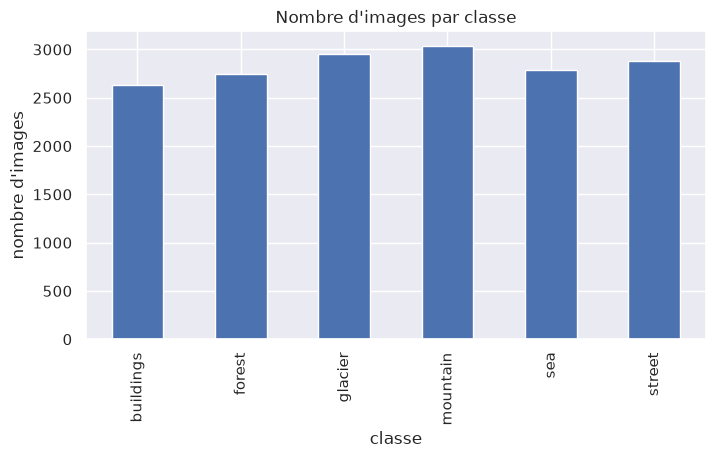

In [38]:

def lister_images(dossier):
    lignes = []
    for classe in CLASSES:
        for nom_fichier in sorted(os.listdir(dossier / classe)):
            lignes.append({"chemin": str(dossier / classe / nom_fichier), "classe": classe})
    return pd.DataFrame(lignes)

df = lister_images(RAW_TRAIN_DIR)

comptage = df["classe"].value_counts().loc[CLASSES]
print(comptage)
print("\n Total : ",len(df), "images")

comptage.plot(kind="bar", figsize=(8, 4), title="Nombre d'images par classe")
plt.ylabel("nombre d'images")
plt.show()


## Étape 3 — Visualiser quelques exemples

**Problème :** il faut *voir* les images pour comprendre ce que le modèle devra reconnaître
(et repérer d'éventuelles ressemblances entre classes, par exemple `glacier` et `mountain`).

**Explication du code :**
- On crée une grille avec 1 ligne par classe et 4 colonnes.
- `.sample(4)` choisit 4 images au hasard dans chaque classe.
- `imshow` affiche l'image, `axis("off")` cache les axes.

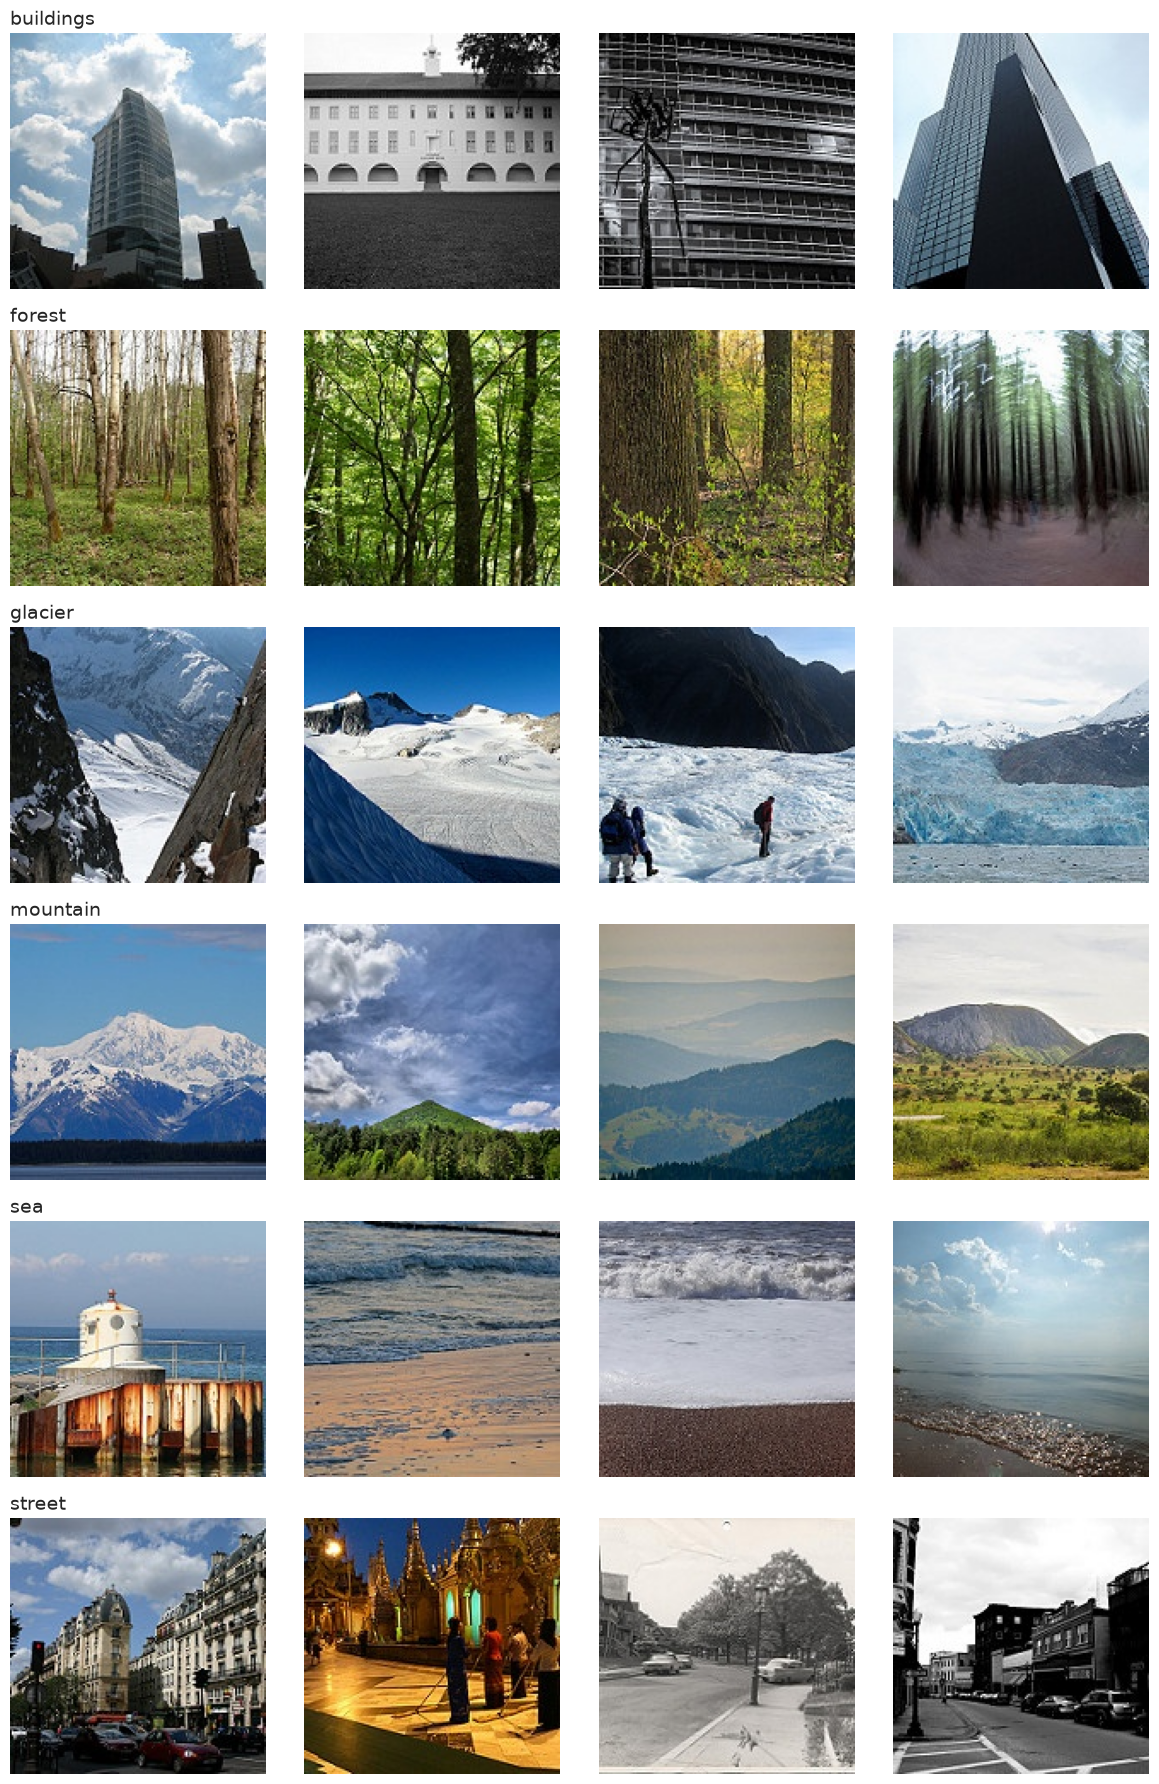

In [39]:
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(12, 18))

for i, classe in enumerate(CLASSES):
    chemins = df[df["classe"] == classe].sample(4, random_state=SEED)["chemin"]
    for j, chemin in enumerate(chemins):
        axes[i, j].imshow(Image.open(chemin))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(classe, loc="left", fontsize=14)

plt.tight_layout()
plt.show()

## Étape 4 — Vérifier dimensions, formats et images problématiques

**Problème :** un réseau de neurones a besoin d'images de **même taille**. De plus, certains fichiers peuvent être
corrompus, en niveaux de gris, ou de taille différente.

**Explication du code :**
- Pour chaque image, `inspecter` lit : largeur, hauteur, mode (`RGB` = couleur), format (`JPEG`...).
- `img.verify()` détecte les fichiers cassés ; le `try/except` évite que le programme plante.
- On affiche ensuite les tailles les plus fréquentes et les images « problématiques ».

In [34]:
def inspecter(chemin):
    try:
        with Image.open(chemin) as img:
            largeur, hauteur = img.size
            mode, format_ = img.mode, img.format
            img.verify()                     
        return largeur, hauteur, mode, format_, True
    except Exception:
        return None, None, None, None, False

colonnes = ["largeur", "hauteur", "mode", "format", "valide"]
infos = df["chemin"].apply(inspecter)
df[colonnes] = pd.DataFrame(infos.tolist(), index=df.index)

print("Tailles les plus frequentes :")
print(df.groupby(["largeur", "hauteur"]).size().sort_values(ascending=False).head()) #nbImages
print("\nModes :", df["mode"].value_counts().to_dict())
print("\n Formats :",df["format"].value_counts().to_dict())

problemes = df[(~df["valide"]) | (df["mode"] != "RGB") | (df["largeur"] != 150) | (df["hauteur"] != 150)]
print("\n Images problematiques : ",len(problemes))
print(problemes.head())


Tailles les plus frequentes :
largeur  hauteur
150      150        16979
         113            7
         135            3
         111            3
         108            2
dtype: int64

Modes : {'RGB': 17034}

 Formats : {'JPEG': 17034}

 Images problematiques :  55
                                     chemin     classe  largeur  hauteur mode  \
2074  data/raw/seg_train/buildings/5358.jpg  buildings      150      124  RGB   
2633     data/raw/seg_train/forest/1004.jpg     forest      150      113  RGB   
2920    data/raw/seg_train/forest/12108.jpg     forest      150      108  RGB   
3193    data/raw/seg_train/forest/14315.jpg     forest      150      133  RGB   
3226    data/raw/seg_train/forest/14609.jpg     forest      150      115  RGB   

     format  valide  
2074   JPEG    True  
2633   JPEG    True  
2920   JPEG    True  
3193   JPEG    True  
3226   JPEG    True  


## Étape 5 — Séparer en Train / Validation / Test

**Problème :** si on évalue le modèle sur les images qu'il a déjà vues, il aura de bonnes notes sans avoir appris à généraliser, Il faut donc 3 ensembles : Train , test , validation

**Explication du code :**
- On coupe les images de `seg_train` en 3 : 70 % **train** / 15 % **validation** / 15 % **test**, **classe par classe** (chaque ensemble garde la même répartition de classes).


In [35]:
def copier(liste_chemins, destination, classe):
    dossier = destination / classe
    dossier.mkdir(parents=True, exist_ok=True)
    for chemin in liste_chemins:
        shutil.copy(chemin, dossier)


random.seed(SEED)
for classe in CLASSES:
    chemins = df[(df["classe"] == classe) & (df["valide"])]["chemin"].tolist()
    random.shuffle(chemins)

    n_val = int(len(chemins) * VAL_RATIO)
    n_test = int(len(chemins) * TEST_RATIO)

    copier(chemins[:n_val], SPLIT_DIR / "val", classe)
    copier(chemins[n_val:n_val + n_test], SPLIT_DIR / "test", classe)
    copier(chemins[n_val + n_test:], SPLIT_DIR / "train", classe)
print("Séparation terminée.")

Séparation terminée.


## Étape 6 — Vérifier la séparation

**Problème :** s'assurer que les 3 ensembles existent et que chaque classe est bien représentée dans chacun.

           train  val  test
buildings   1840  394   394
forest      1923  411   411
glacier     2071  443   443
mountain    2127  455   455
sea         1950  417   417
street      2019  432   432

Totaux : {'train': 11930, 'val': 2552, 'test': 2552}


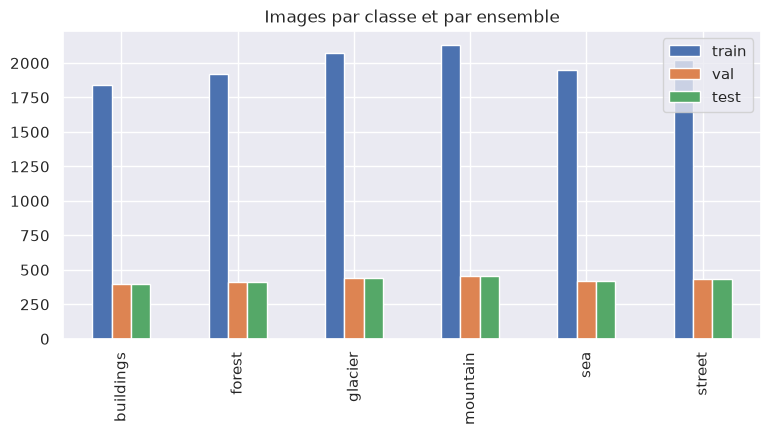

In [36]:
resume = {}
for ensemble in ["train", "val", "test"]:
    resume[ensemble] = {classe: len(os.listdir(SPLIT_DIR / ensemble / classe)) for classe in CLASSES}

df_resume = pd.DataFrame(resume)
print(df_resume)
print("\nTotaux :", df_resume.sum().to_dict())

df_resume.plot(kind="bar", figsize=(9, 4), title="Images par classe et par ensemble")
plt.show()